# Configuración Inicial

Se instalan y cargan las librerías necesarias para el proyecto:
- **ucimlrepo:** descarga del dataset directamente desde el repositorio UCI.
- **pandas y numpy:** manipulación y transformación de los datos.
- **matplotlib y seaborn:** visualización.

In [24]:
!pip install ucimlrepo

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# Comprensión del Negocio

## Contexto
Tetouan es una ciudad del norte de Marruecos cuya red eléctrica se divide en tres zonas de distribución. El operador de distribución debe equilibrar en todo momento la energía que suministra con la que consume la ciudad: si la demanda supera lo previsto, la red se sobrecarga; si se sobreestima, se genera o compra energía que no se usa, lo que implica costos innecesarios.

## Problema
El operador conoce el consumo cuando ya ocurrió. Para planificar la carga necesita saber con anticipación cuánta energía se va a demandar, especialmente en los momentos de mayor consumo.

## Objetivo del proyecto
Estimar el consumo eléctrico de la **Zona 1** de Tetouan con **1 hora de anticipación** (6 periodos de 10 minutos), a partir de la información disponible en el momento de la predicción.

## Información disponible al momento de predecir
Si la predicción se hace al cierre del periodo t, solo se conoce:

| Información | ¿Disponible en t? |
|---|---|
| Consumo de las tres zonas hasta t | Sí |
| Clima observado hasta t | Sí |
| Calendario del periodo a predecir (hora, día, mes) | Sí, se conoce de antemano |
| Clima en t+6 | No (el dataset no incluye pronósticos) |
| Consumo en t+6 | No, es lo que se predice |

## Justificación del horizonte
- Predecir 10 minutos adelante tiene poco valor operativo: el consumo casi no cambia en ese intervalo y el operador no alcanza a reaccionar.
- Una hora de anticipación permite ajustar la generación o redistribuir carga antes de que ocurra un pico.

## Criterio de éxito
El modelo será útil si su error es menor que el de una referencia simple (*baseline* de persistencia), que asume que el consumo dentro de una hora será igual al consumo actual. Si no supera esa referencia, no aporta valor al negocio.

# Comprensión de los Datos

## Fuente
Dataset *Power Consumption of Tetouan City* del repositorio UCI Machine Learning (ID 849). Contiene registros cada 10 minutos durante el año 2017.

## Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| DateTime | Fecha | Momento del registro (cada 10 minutos) |
| Temperature | Continua | Temperatura de la ciudad (°C) |
| Humidity | Continua | Humedad relativa (%) |
| Wind Speed | Continua | Velocidad del viento |
| general diffuse flows | Continua | Radiación solar difusa general |
| diffuse flows | Continua | Radiación solar difusa |
| Zone 1 Power Consumption | Continua | Consumo eléctrico de la Zona 1 (kW) |
| Zone 2 Power Consumption | Continua | Consumo eléctrico de la Zona 2 (kW) |
| Zone 3 Power Consumption | Continua | Consumo eléctrico de la Zona 3 (kW) |

In [26]:
# Dataset: https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city
power_consumption_of_tetouan_city = fetch_ucirepo(id=849)

X_raw = power_consumption_of_tetouan_city.data.features
y_raw = power_consumption_of_tetouan_city.data.targets

print("Resumen del dataset")
print(f"Cantidad de registros: {X_raw.shape[0]}")
print(f"Cantidad de variables predictoras: {X_raw.shape[1]}")
print(f"Cantidad de variables objetivo: {y_raw.shape[1]}")

df = X_raw.join(y_raw)

print()
df.info()

print()
print(power_consumption_of_tetouan_city.variables)

print("\n--- Resumen Estadístico ---")
display(df.describe().T)

display(df.head())

Resumen del dataset
Cantidad de registros: 52416
Cantidad de variables predictoras: 6
Cantidad de variables objetivo: 3

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   DateTime                   52416 non-null  object 
 1   Temperature                52416 non-null  float64
 2   Humidity                   52416 non-null  float64
 3   Wind Speed                 52416 non-null  float64
 4   general diffuse flows      52416 non-null  float64
 5   diffuse flows              52416 non-null  float64
 6   Zone 1 Power Consumption   52416 non-null  float64
 7   Zone 2  Power Consumption  52416 non-null  float64
 8   Zone 3  Power Consumption  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB

                        name     role        type demographic  \
0                   DateTime  Feature

,count,mean,std,min,25%,50%,75%,max
Temperature,52416.0,18.810024,5.815476,3.247000,14.410000,18.780000,22.890000,40.01000
Humidity,52416.0,68.259518,15.551177,11.340000,58.310000,69.860000,81.400000,94.80000
Wind Speed,52416.0,1.959489,2.348862,0.050000,0.078000,0.086000,4.915000,6.48300
general diffuse flows,52416.0,182.696614,264.400960,0.004000,0.062000,5.035500,319.600000,1163.00000
diffuse flows,52416.0,75.028022,124.210949,0.011000,0.122000,4.456000,101.000000,936.00000
Zone 1 Power Consumption,52416.0,32344.970564,7130.562564,13895.696200,26310.668692,32265.920340,37309.018185,52204.39512
Zone 2 Power Consumption,52416.0,21042.509082,5201.465892,8560.081466,16980.766032,20823.168405,24713.717520,37408.86076
Zone 3 Power Consumption,52416.0,17835.406218,6622.165099,5935.174070,13129.326630,16415.117470,21624.100420,47598.32636


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


## Duplicados y valores faltantes

In [27]:
print(f"Filas duplicadas: {df.duplicated().sum()}")

print("\n--- Valores faltantes por columna ---")
print(df.isnull().sum())
print(f"\nTotal de valores faltantes: {df.isnull().sum().sum()}")

Filas duplicadas: 0

--- Valores faltantes por columna ---
DateTime                     0
Temperature                  0
Humidity                     0
Wind Speed                   0
general diffuse flows        0
diffuse flows                0
Zone 1 Power Consumption     0
Zone 2  Power Consumption    0
Zone 3  Power Consumption    0
dtype: int64

Total de valores faltantes: 0


## Nombres de columnas y tipos de datos

Algunas columnas tienen espacios dobles en su nombre (por ejemplo, "Zone 2  Power Consumption"), lo que provoca errores al referenciarlas. Además, DateTime se carga como texto (object). Para poder explorar el comportamiento temporal, se normalizan los nombres y se convierte DateTime a tipo fecha.

In [28]:
print("Columnas originales:", df.columns.tolist())

# Normalizar espacios en los nombres de columnas
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)
print("Columnas corregidas:", df.columns.tolist())

# Conversión de DateTime
print("\nAntes:", df["DateTime"].dtype)
df["DateTime"] = pd.to_datetime(df["DateTime"], format="%m/%d/%Y %H:%M")
print("Después:", df["DateTime"].dtype)
print(f"Fechas no convertidas (NaT): {df['DateTime'].isnull().sum()}")

# Orden cronológico
df = df.sort_values("DateTime").reset_index(drop=True)

ZONES = ["Zone 1 Power Consumption", "Zone 2 Power Consumption", "Zone 3 Power Consumption"]

Columnas originales: ['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption']
Columnas corregidas: ['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']

Antes: object
Después: datetime64[ns]
Fechas no convertidas (NaT): 0


## Consistencia temporal

Los registros deberían estar cada 10 minutos (144 por día). Se verifica que no existan huecos, fechas duplicadas ni intervalos irregulares.

In [29]:
print(f"Fecha inicial: {df['DateTime'].min()}")
print(f"Fecha final: {df['DateTime'].max()}")
print(f"Días cubiertos: {df['DateTime'].dt.date.nunique()}")
print(f"Fechas duplicadas: {df['DateTime'].duplicated().sum()}")

intervalos = df["DateTime"].diff().dropna()
print("\n--- Intervalos entre registros ---")
print(intervalos.value_counts())

huecos = (intervalos > pd.Timedelta(minutes=10)).sum()
print(f"\nHuecos en la serie: {huecos}")

Fecha inicial: 2017-01-01 00:00:00
Fecha final: 2017-12-30 23:50:00
Días cubiertos: 364
Fechas duplicadas: 0

--- Intervalos entre registros ---
DateTime
0 days 00:10:00    52415
Name: count, dtype: int64

Huecos en la serie: 0


Todos los registros están espaciados exactamente cada 10 minutos, sin huecos ni fechas duplicadas. El dataset abarca del 1 de enero al 30 de diciembre de 2017 (364 días × 144 registros = 52 416), por lo que no falta información dentro del periodo.

## Valores atípicos (criterio IQR)

Se usa el criterio del rango intercuartílico: un valor es atípico si está por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR. Primero se revisan las variables climáticas y luego cada zona de consumo por separado.

### Variables climáticas

In [30]:
clima_cols = ["Temperature", "Humidity", "Wind Speed", "general diffuse flows", "diffuse flows"]

resumen = []
for col in clima_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    resumen.append({
        "Variable": col,
        "Outliers": n,
        "% del total": round(100 * n / len(df), 1),
        "Mínimo": df[col].min(),
        "Máximo": df[col].max(),
        "Asimetría": round(df[col].skew(), 3),
    })

display(pd.DataFrame(resumen))

,Variable,Outliers,% del total,Mínimo,Máximo,Asimetría
0,Temperature,142,0.3,3.247,40.010,0.197
1,Humidity,291,0.6,11.340,94.800,-0.625
2,Wind Speed,0,0.0,0.050,6.483,0.462
3,general diffuse flows,2315,4.4,0.004,1163.000,1.307
4,diffuse flows,4571,8.7,0.011,936.000,2.457


- **general diffuse flows y diffuse flows:** la radiación vale casi 0 toda la noche y sube mucho al mediodía, por lo que su distribución es sesgada y sigue el ciclo día/noche.
- **Temperature y Humidity:** son pocos casos y están dentro de rangos posibles para Tetouan.

### Zone 1 Power Consumption

In [31]:
col = "Zone 1 Power Consumption"

q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
outliers_z1 = df[(df[col] < lim_inf) | (df[col] > lim_sup)]

print(col)
print(f"Q1: {q1:,.2f} | Mediana: {df[col].median():,.2f} | Q3: {q3:,.2f}")
print(f"Media: {df[col].mean():,.2f}")
print(f"Límite inferior: {lim_inf:,.2f} | Límite superior: {lim_sup:,.2f}")
print(f"Mínimo: {df[col].min():,.2f} | Máximo: {df[col].max():,.2f}")
print(f"Asimetría: {df[col].skew():.3f}")
print(f"Valores fuera del IQR: {len(outliers_z1)} ({100 * len(outliers_z1) / len(df):.1f}%)")
print(f"Valores <= 0: {(df[col] <= 0).sum()}")

if len(outliers_z1) > 0:
    print("\nOutliers por mes:")
    print(outliers_z1["DateTime"].dt.month.value_counts().sort_index())

Zone 1 Power Consumption
Q1: 26,310.67 | Mediana: 32,265.92 | Q3: 37,309.02
Media: 32,344.97
Límite inferior: 9,813.14 | Límite superior: 53,806.54
Mínimo: 13,895.70 | Máximo: 52,204.40
Asimetría: 0.229
Valores fuera del IQR: 0 (0.0%)
Valores <= 0: 0


Zone 1 tiene una media y una mediana muy cercanas, lo que indica una distribución casi simétrica, y no presenta valores fuera del IQR ni valores en cero o negativos. Sus datos no requieren tratamiento.

### Zone 2 Power Consumption

In [32]:
col = "Zone 2 Power Consumption"

q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
outliers_z2 = df[(df[col] < lim_inf) | (df[col] > lim_sup)]

print(col)
print(f"Q1: {q1:,.2f} | Mediana: {df[col].median():,.2f} | Q3: {q3:,.2f}")
print(f"Media: {df[col].mean():,.2f}")
print(f"Límite inferior: {lim_inf:,.2f} | Límite superior: {lim_sup:,.2f}")
print(f"Mínimo: {df[col].min():,.2f} | Máximo: {df[col].max():,.2f}")
print(f"Asimetría: {df[col].skew():.3f}")
print(f"Valores fuera del IQR: {len(outliers_z2)} ({100 * len(outliers_z2) / len(df):.1f}%)")
print(f"Valores <= 0: {(df[col] <= 0).sum()}")

if len(outliers_z2) > 0:
    print("\nOutliers por mes:")
    print(outliers_z2["DateTime"].dt.month.value_counts().sort_index())
    print("\nOutliers por hora:")
    print(outliers_z2["DateTime"].dt.hour.value_counts().sort_index())

Zone 2 Power Consumption
Q1: 16,980.77 | Mediana: 20,823.17 | Q3: 24,713.72
Media: 21,042.51
Límite inferior: 5,381.34 | Límite superior: 36,313.14
Mínimo: 8,560.08 | Máximo: 37,408.86
Asimetría: 0.329
Valores fuera del IQR: 7 (0.0%)
Valores <= 0: 0

Outliers por mes:
DateTime
7    2
8    5
Name: count, dtype: int64

Outliers por hora:
DateTime
19    3
20    4
Name: count, dtype: int64


Zone 2 presenta muy pocos valores fuera del IQR (menos del 0.1% del total) y un leve sesgo a la derecha. *(Completar con el mes y la hora en que caen según la salida anterior.)* Al ser tan pocos y estar dentro de un rango plausible de consumo, se consideran picos reales de demanda.

### Zone 3 Power Consumption

In [33]:
col = "Zone 3 Power Consumption"

q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
outliers_z3 = df[(df[col] < lim_inf) | (df[col] > lim_sup)]

print(col)
print(f"Q1: {q1:,.2f} | Mediana: {df[col].median():,.2f} | Q3: {q3:,.2f}")
print(f"Media: {df[col].mean():,.2f}")
print(f"Límite inferior: {lim_inf:,.2f} | Límite superior: {lim_sup:,.2f}")
print(f"Mínimo: {df[col].min():,.2f} | Máximo: {df[col].max():,.2f}")
print(f"Asimetría: {df[col].skew():.3f}")
print(f"Valores fuera del IQR: {len(outliers_z3)} ({100 * len(outliers_z3) / len(df):.1f}%)")
print(f"Valores <= 0: {(df[col] <= 0).sum()}")

# ¿En qué meses caen los valores por encima del límite superior del IQR?
picos_z3 = df[df[col] > lim_sup]
print(f"\nValores por encima del límite superior ({lim_sup:,.2f}): {len(picos_z3)}")
print("Distribución por mes:")
print(picos_z3["DateTime"].dt.month.value_counts().sort_index())

Zone 3 Power Consumption
Q1: 13,129.33 | Mediana: 16,415.12 | Q3: 21,624.10
Media: 17,835.41
Límite inferior: 387.17 | Límite superior: 34,366.26
Mínimo: 5,935.17 | Máximo: 47,598.33
Asimetría: 1.024
Valores fuera del IQR: 1191 (2.3%)
Valores <= 0: 0

Valores por encima del límite superior (34,366.26): 1191
Distribución por mes:
DateTime
7    760
8    431
Name: count, dtype: int64


Zone 3 es la zona con más valores atípicos y el sesgo a la derecha más marcado: la media supera claramente a la mediana. Los valores por encima del límite superior del IQR se concentran en los meses de verano (julio y agosto, según la salida anterior), los de más calor. Por lo tanto, corresponden a demanda real de temporada y no a errores de medición.

## Comportamiento temporal de los picos de consumo

Además de la media, la mediana y el IQR, se analiza **cuándo** ocurren los picos de cada zona: a lo largo del año, por hora del día, por día de la semana y por mes. Se grafica el máximo (pico) y, como referencia, el promedio.

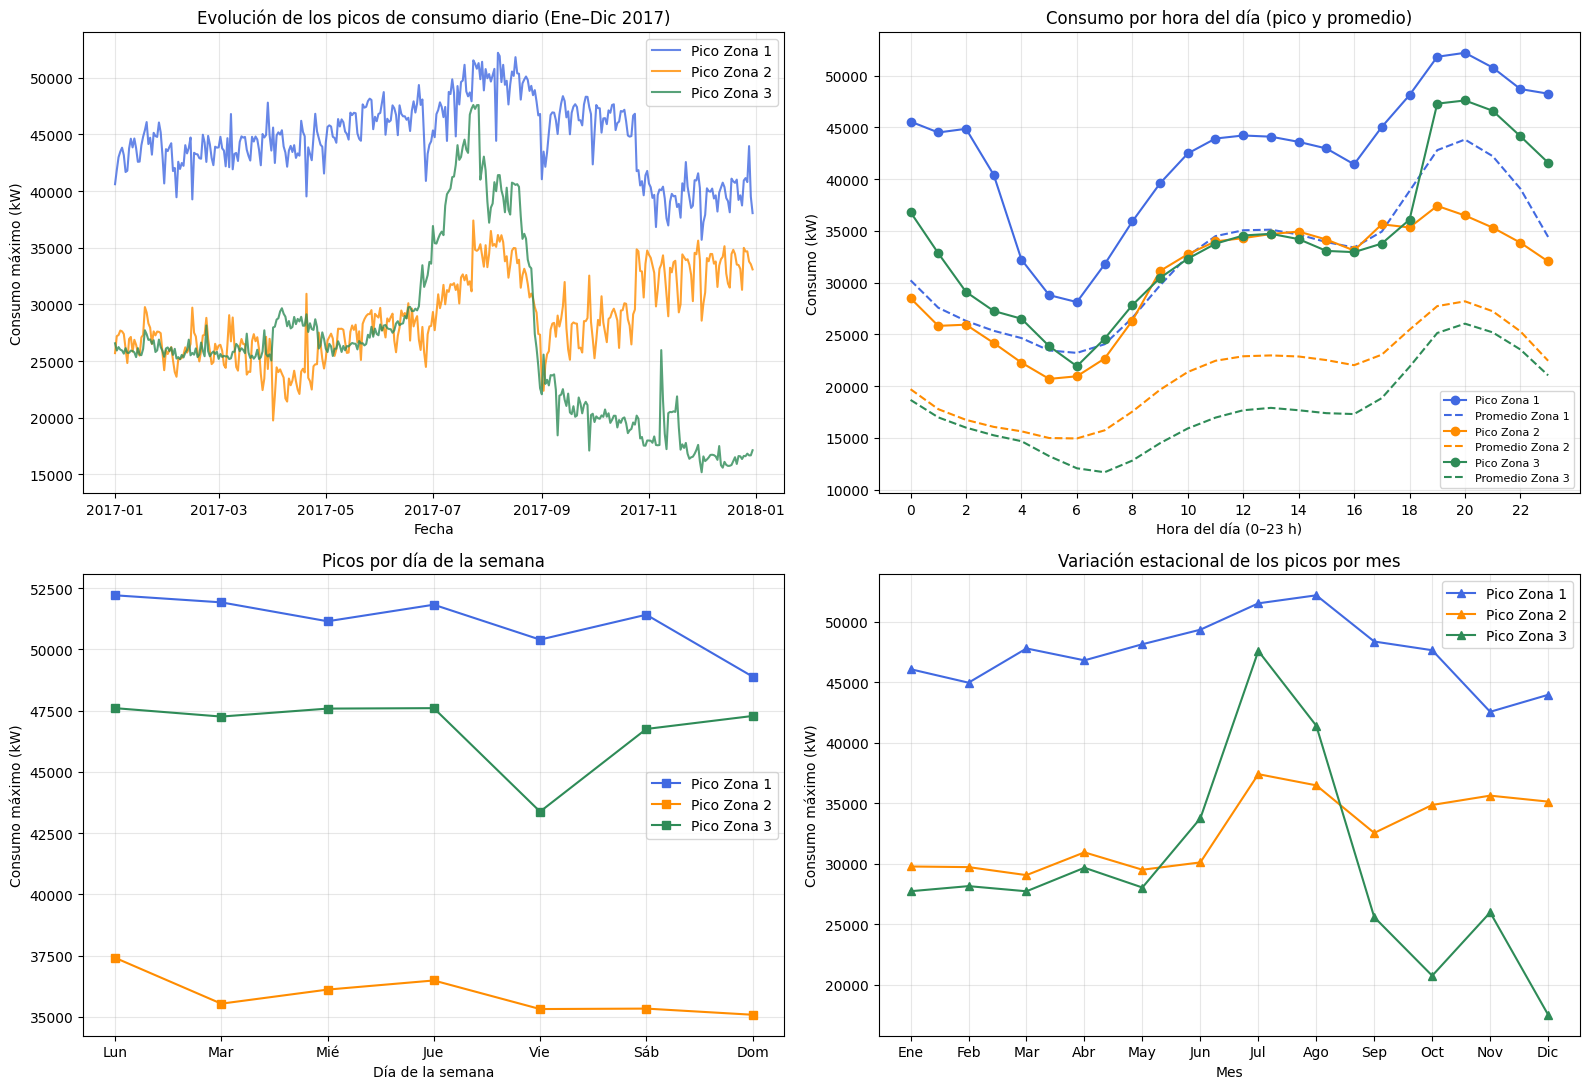

Hora de mayor consumo promedio por zona:
Zone 1 Power Consumption    20
Zone 2 Power Consumption    20
Zone 3 Power Consumption    20
dtype: int32


In [34]:
df_eda = df.copy()
df_eda["Hora"] = df_eda["DateTime"].dt.hour
df_eda["Mes"] = df_eda["DateTime"].dt.month
df_eda["DiaSemana"] = df_eda["DateTime"].dt.dayofweek

zone_labels = ["Zona 1", "Zona 2", "Zona 3"]
colors = ["royalblue", "darkorange", "seagreen"]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Picos diarios a lo largo del año
picos_diarios = df_eda.groupby(df_eda["DateTime"].dt.date)[ZONES].max()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[0, 0].plot(picos_diarios.index, picos_diarios[col], label=f"Pico {label}", color=color, alpha=0.8)
axes[0, 0].set_title("Evolución de los picos de consumo diario (Ene–Dic 2017)")
axes[0, 0].set_xlabel("Fecha")
axes[0, 0].set_ylabel("Consumo máximo (kW)")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Perfil por hora del día: pico (línea continua) y promedio (línea punteada)
picos_horarios = df_eda.groupby("Hora")[ZONES].max()
prom_horarios = df_eda.groupby("Hora")[ZONES].mean()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[0, 1].plot(picos_horarios.index, picos_horarios[col], label=f"Pico {label}", color=color, marker="o")
    axes[0, 1].plot(prom_horarios.index, prom_horarios[col], label=f"Promedio {label}", color=color, linestyle="--")
axes[0, 1].set_title("Consumo por hora del día (pico y promedio)")
axes[0, 1].set_xlabel("Hora del día (0–23 h)")
axes[0, 1].set_ylabel("Consumo (kW)")
axes[0, 1].set_xticks(range(0, 24, 2))
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(alpha=0.3)

# 3. Picos por día de la semana
dias_labels = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
picos_semanales = df_eda.groupby("DiaSemana")[ZONES].max()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[1, 0].plot(dias_labels, picos_semanales[col], label=f"Pico {label}", color=color, marker="s")
axes[1, 0].set_title("Picos por día de la semana")
axes[1, 0].set_xlabel("Día de la semana")
axes[1, 0].set_ylabel("Consumo máximo (kW)")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Picos por mes
meses_labels = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
picos_mensuales = df_eda.groupby("Mes")[ZONES].max()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[1, 1].plot(meses_labels, picos_mensuales[col], label=f"Pico {label}", color=color, marker="^")
axes[1, 1].set_title("Variación estacional de los picos por mes")
axes[1, 1].set_xlabel("Mes")
axes[1, 1].set_ylabel("Consumo máximo (kW)")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Hora en que cada zona alcanza su mayor consumo promedio
print("Hora de mayor consumo promedio por zona:")
print(prom_horarios.idxmax())

**Interpretación de los picos:** *(completar según los gráficos)*
- **Por hora:** el consumo de las tres zonas es mínimo en la madrugada y alcanza su máximo en la noche, alrededor de la hora indicada en la salida anterior.
- **Por día de la semana:** *[describir si hay diferencias entre días laborables y fin de semana]*.
- **Por mes:** Zone 3 presenta picos muy por encima del resto del año en julio y agosto, que explican sus valores atípicos. Zone 1 y Zone 2 muestran *[describir]*.

Esto confirma que los picos no son errores aislados, sino que siguen patrones diarios y estacionales. Por ello, el modelo necesita variables de calendario y del consumo en periodos anteriores.

## Hallazgos de la exploración

1. **Duplicados:** no existen filas duplicadas.
2. **Valores faltantes:** ninguna columna presenta valores nulos, lo que coincide con la metadata de UCI.
3. **Tipos de datos:** DateTime se cargaba como texto y se convirtió a tipo fecha; algunos nombres de columnas tenían espacios dobles.
4. **Continuidad temporal:** registros cada 10 minutos sin huecos del 01/01/2017 al 30/12/2017.
5. **Valores atípicos:** se concentran en Zone 3 (picos de verano) y en la radiación solar (ciclo día/noche). Zone 1 no presenta outliers.
6. **Comportamiento temporal:** el consumo sigue un ciclo diario marcado y Zone 3 tiene una fuerte estacionalidad en verano.

# Preparación de los Datos

En esta fase se transforman los datos para que respondan al problema definido: estimar el consumo de la Zona 1 una hora adelante, usando solo información disponible en el momento de predecir.

## Cambios respecto a la entrega anterior

- Se eliminaron las variables creadas a partir de hipótesis no demostradas con los datos (Is_Heatwave, Muggy_Comfort_Risk, Dry_Heat_Risk, Is_Wind).
- Se transformó DateTime en variables de tiempo: hora, minuto del día, día, mes, día de la semana, día del año y fin de semana, con codificación cíclica.
- Se revisaron los picos de las tres zonas considerando su comportamiento temporal (por día, hora, día de la semana y mes).
- Se utilizará únicamente Zone 1 como variable objetivo; Zone 2 y Zone 3 se usan como predictoras.
- Se predecirá el consumo 6 periodos adelante, equivalente a 1 hora.

## Tratamiento de valores atípicos

- **Zone 3 Power Consumption:** los registros por encima del límite superior del IQR se concentran en julio y agosto, los meses de más calor. Corresponden a demanda real de verano, no a errores de medición.
- **general diffuse flows y diffuse flows:** la radiación vale casi 0 toda la noche y sube mucho al mediodía; su distribución sesgada sigue el ciclo día/noche.
- **Temperature y Humidity:** son pocos casos y están dentro de rangos posibles para Tetouan.
- **Zone 1** no tiene outliers y **Zone 2** solo unos pocos.

**Decisión:** no se elimina ni se recorta ningún valor. Todos son mediciones plausibles, y quitar los picos haría que el modelo subestime justo los periodos de mayor demanda, que son los que el negocio necesita anticipar.

## Variables descartadas

En la entrega anterior se crearon variables basadas en umbrales definidos manualmente (Is_Heatwave, Muggy_Comfort_Risk, Dry_Heat_Risk, Is_Wind). Se eliminaron porque esos umbrales eran hipótesis no demostradas con los datos. En su lugar, Temperature, Humidity y Wind Speed se conservan como variables continuas, para que el modelo aprenda directamente su relación con el consumo.

## Selección de la variable objetivo

Se evaluó si plantear tres modelos independientes, un modelo multisalida o uno solo. Para decidirlo se compara el nivel de consumo y la relación entre las tres zonas.

--- Consumo promedio por zona (kW) ---
Zone 1 Power Consumption    32345.0
Zone 2 Power Consumption    21043.0
Zone 3 Power Consumption    17835.0
dtype: float64

--- Correlación entre zonas ---


,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
Zone 1 Power Consumption,1.000,0.835,0.751
Zone 2 Power Consumption,0.835,1.000,0.571
Zone 3 Power Consumption,0.751,0.571,1.000


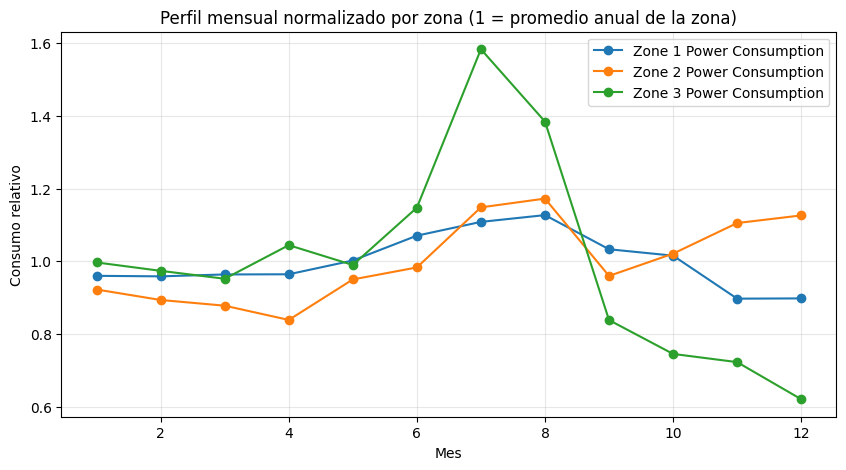

In [35]:
print("--- Consumo promedio por zona (kW) ---")
print(df[ZONES].mean().round(0))

print("\n--- Correlación entre zonas ---")
display(df[ZONES].corr().round(3))

# Comparación del perfil mensual normalizado (cada zona dividida por su propio promedio)
perfil_mensual = df.groupby(df["DateTime"].dt.month)[ZONES].mean()
perfil_norm = perfil_mensual / perfil_mensual.mean()

perfil_norm.plot(figsize=(10, 5), marker="o")
plt.title("Perfil mensual normalizado por zona (1 = promedio anual de la zona)")
plt.xlabel("Mes")
plt.ylabel("Consumo relativo")
plt.grid(alpha=0.3)
plt.show()

Se decidió modelar **únicamente Zone 1 Power Consumption**, por las siguientes razones:

- Zone 1 es la zona de mayor consumo de la ciudad, por lo que concentra la mayor parte de la demanda que el operador necesita anticipar.
- Su comportamiento es estable y sin valores atípicos, mientras que Zone 3 presenta una estacionalidad de verano muy marcada (ver el perfil mensual normalizado) que requeriría un tratamiento distinto.
- Las zonas no se comportan igual a lo largo del año, por lo que un modelo multisalida obligaría a compartir patrones que no son comunes.

Zone 2 y Zone 3 no se descartan: se usan como **variables predictoras** mediante sus rezagos, ya que su consumo reciente aporta información sobre la demanda general de la ciudad.

## Unidad de análisis y variable objetivo

- **Unidad de análisis:** un periodo de 10 minutos en la ciudad de Tetouan. Cada fila contiene el clima observado y el consumo de las tres zonas en ese periodo.
- **Variable objetivo:** el consumo de la Zona 1 una hora después (`Target_Zone1_t_plus_6`, es decir, 6 periodos adelante).
- **Momento de predicción:** al cierre del periodo t, usando solo información disponible hasta t.

## Variables temporales y codificación

El consumo eléctrico sigue ciclos diarios, semanales y anuales, por lo que se extraen componentes de DateTime: hora, minuto del día, día, mes, día de la semana, día del año y fin de semana.

El dataset no contiene variables categóricas originales. Sin embargo, las variables de tiempo son cíclicas (las 23:50 están cerca de las 00:00, y el domingo cerca del lunes), por lo que se codifican con seno y coseno para que el modelo capture esa continuidad.

In [36]:
# Componentes temporales
df["Hour"] = df["DateTime"].dt.hour
df["MinuteOfDay"] = df["DateTime"].dt.hour * 60 + df["DateTime"].dt.minute
df["Day"] = df["DateTime"].dt.day
df["Month"] = df["DateTime"].dt.month
df["DayOfWeek"] = df["DateTime"].dt.dayofweek          # 0 = lunes, 6 = domingo
df["DayOfYear"] = df["DateTime"].dt.dayofyear
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)   # sábado y domingo

# Codificación cíclica (seno / coseno)
# Ciclo diario (1 día = 1440 minutos)
df["Time_Sin"] = np.sin(2 * np.pi * df["MinuteOfDay"] / 1440)
df["Time_Cos"] = np.cos(2 * np.pi * df["MinuteOfDay"] / 1440)
# Ciclo semanal (7 días)
df["Week_Sin"] = np.sin(2 * np.pi * df["DayOfWeek"] / 7)
df["Week_Cos"] = np.cos(2 * np.pi * df["DayOfWeek"] / 7)
# Ciclo anual (365 días)
df["Year_Sin"] = np.sin(2 * np.pi * (df["DayOfYear"] - 1) / 365)
df["Year_Cos"] = np.cos(2 * np.pi * (df["DayOfYear"] - 1) / 365)

# Verificación de IsWeekend: debe marcar solo sábado (5) y domingo (6)
print(df.groupby("DayOfWeek")["IsWeekend"].max())

display(df[["DateTime", "Hour", "Day", "Month", "DayOfWeek", "IsWeekend",
            "Time_Sin", "Time_Cos", "Week_Sin", "Week_Cos"]].head())

DayOfWeek
0    0
1    0
2    0
3    0
4    0
5    1
6    1
Name: IsWeekend, dtype: int64


,DateTime,Hour,Day,Month,DayOfWeek,IsWeekend,Time_Sin,Time_Cos,Week_Sin,Week_Cos
0,2017-01-01 00:00:00,0,1,1,6,1,0.000000,1.000000,-0.781831,0.62349
1,2017-01-01 00:10:00,0,1,1,6,1,0.043619,0.999048,-0.781831,0.62349
2,2017-01-01 00:20:00,0,1,1,6,1,0.087156,0.996195,-0.781831,0.62349
3,2017-01-01 00:30:00,0,1,1,6,1,0.130526,0.991445,-0.781831,0.62349
4,2017-01-01 00:40:00,0,1,1,6,1,0.173648,0.984808,-0.781831,0.62349


**Limitación:** el dataset abarca un solo año. Como la partición es cronológica, el modelo nunca verá noviembre y diciembre durante el entrenamiento, por lo que el patrón anual (Year_Sin, Year_Cos, DayOfYear, Month) no se puede aprender completamente.

## Variable objetivo y rezagos

Los registros son cada 10 minutos. Se toma **t** como el periodo actual; **t+n** indica n periodos adelante y **t−n**, n periodos atrás.

- **Objetivo:** consumo de la Zona 1 en **t+6** (1 hora después).
- **Rezagos de las tres zonas:** t, t−1 (10 min), t−2 (20 min) y t−6 (1 hora).
- **Rezago diario de Zone 1:** mismo momento del día anterior al periodo que se predice (t+6−144 = t−138). Captura el ciclo diario que se observó en los picos.
- **Estadísticas móviles de Zone 1:** media y desviación estándar de la última hora (t−5 a t).

Todas estas variables usan solo información conocida en t.

In [37]:
HORIZONTE = 6   # 6 periodos de 10 minutos = 1 hora
TARGET = "Target_Zone1_t_plus_6"

# Variable objetivo: consumo de Zone 1 una hora adelante
df[TARGET] = df["Zone 1 Power Consumption"].shift(-HORIZONTE)

# Rezagos de las tres zonas
lags = [0, 1, 2, 6]
for lag in lags:
    suffix = "_t" if lag == 0 else f"_t_minus_{lag}"
    df[f"Zone1{suffix}"] = df["Zone 1 Power Consumption"].shift(lag)
    df[f"Zone2{suffix}"] = df["Zone 2 Power Consumption"].shift(lag)
    df[f"Zone3{suffix}"] = df["Zone 3 Power Consumption"].shift(lag)

# Rezago diario: mismo momento del día anterior al periodo que se predice
df["Zone1_lag_24h"] = df["Zone 1 Power Consumption"].shift(144 - HORIZONTE)

# Estadísticas móviles de la última hora (t-5 a t)
df["Zone1_Rolling_Mean_1h"] = df["Zone 1 Power Consumption"].rolling(window=6).mean()
df["Zone1_Rolling_Std_1h"] = df["Zone 1 Power Consumption"].rolling(window=6).std()

# Eliminación de filas sin historial suficiente o sin objetivo
df_model = df.dropna().reset_index(drop=True)

print(f"Dimensiones del dataset original: {df.shape}")
print(f"Dimensiones del dataset listo para modelar: {df_model.shape}")
print(f"Filas eliminadas: {len(df) - len(df_model)}")

display(df_model[["DateTime", "Zone1_t", "Zone1_t_minus_1", "Zone1_lag_24h",
                  "Zone1_Rolling_Mean_1h", TARGET]].head())

Dimensiones del dataset original: (52416, 38)
Dimensiones del dataset listo para modelar: (52272, 38)
Filas eliminadas: 144


,DateTime,Zone1_t,Zone1_t_minus_1,Zone1_lag_24h,Zone1_Rolling_Mean_1h,Target_Zone1_t_plus_6
0,2017-01-01 23:00:00,32117.46835,33077.46835,34055.69620,34166.075947,26703.79747
1,2017-01-01 23:10:00,31357.97468,32117.46835,29814.68354,33326.582275,26169.11392
2,2017-01-01 23:20:00,30701.77215,31357.97468,29128.10127,32562.025313,25622.27848
3,2017-01-01 23:30:00,29681.01266,30701.77215,28228.86076,31769.113922,24972.15190
4,2017-01-01 23:40:00,28830.37975,29681.01266,27335.69620,30961.012657,24437.46835


Se eliminan las primeras filas, que no tienen historial suficiente para el rezago de 24 horas, y las últimas 6, que no tienen objetivo t+6. No se imputa ningún valor, para no introducir información artificial ni del futuro.

## Correlación de las variables con el objetivo y chequeo de calidad

--- TOP 10 VARIABLES MÁS CORRELACIONADAS CON EL TARGET (t+6) ---
Zone1_lag_24h            0.961645
Zone1_t                  0.912919
Zone1_t_minus_1          0.887717
Zone1_t_minus_2          0.860533
Zone1_Rolling_Mean_1h    0.851158
Zone2_t                  0.765888
Zone2_t_minus_1          0.745149
Zone1_t_minus_6          0.736424
Zone2_t_minus_2          0.722668
Hour                     0.684834
dtype: float64

--- TOP 5 VARIABLES MENOS CORRELACIONADAS (MÁS CERCANAS A 0) ---
DayOfYear    0.006416
Month        0.007684
Day          0.024114
Week_Cos     0.028660
Week_Sin     0.065160
dtype: float64


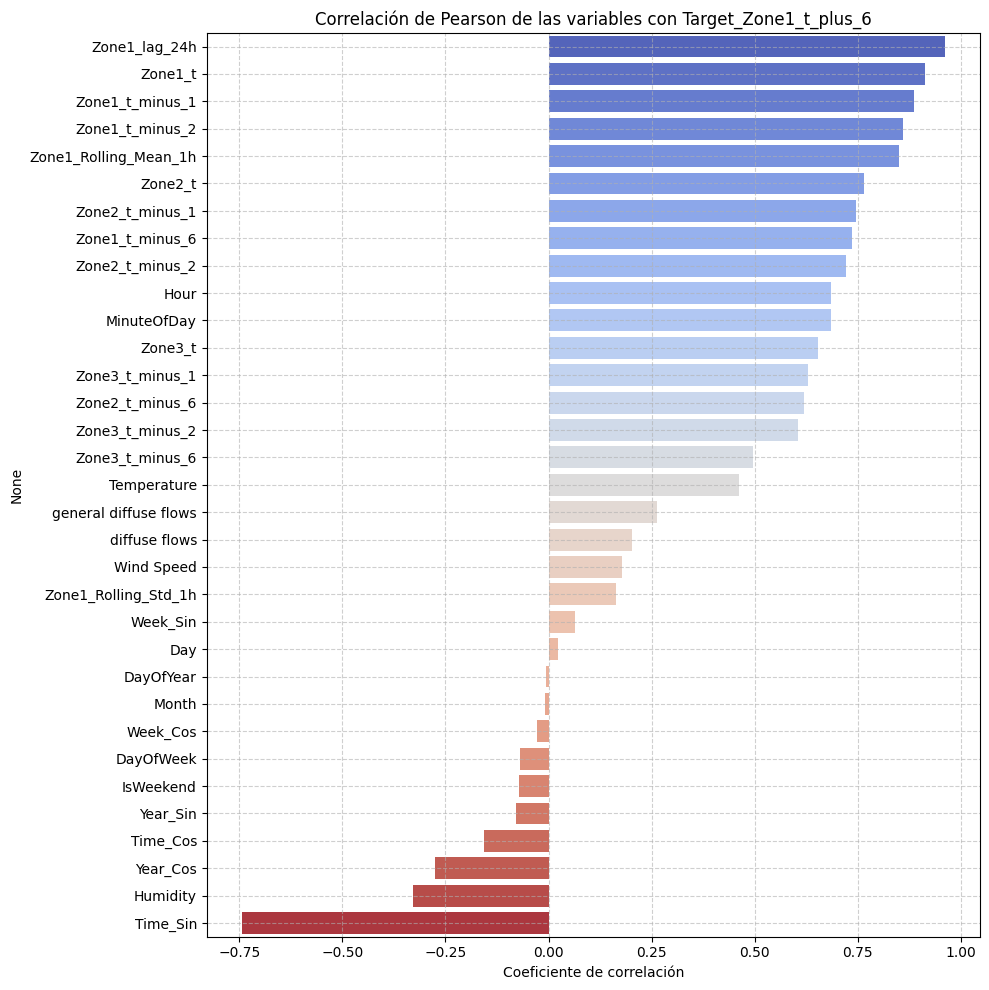


--- Chequeo de Calidad ---
Valores nulos en dataset final: 0
Valores infinitos en dataset final: 0


In [38]:

cols_to_drop = [
    "DateTime",                   # No es predictora
    "Zone 1 Power Consumption",   # Duplicado de Zone1_t
    "Zone 2 Power Consumption",   # Duplicado de Zone2_t
    "Zone 3 Power Consumption",   # Duplicado de Zone3_t
    TARGET,                       # Se separa como y
]
feature_cols = [c for c in df_model.columns if c not in cols_to_drop]

correlations = (
    df_model[feature_cols]
    .apply(lambda col: col.corr(df_model[TARGET]))
    .sort_values(ascending=False)
)

print("--- TOP 10 VARIABLES MÁS CORRELACIONADAS CON EL TARGET (t+6) ---")
print(correlations.head(10))
print("\n--- TOP 5 VARIABLES MENOS CORRELACIONADAS (MÁS CERCANAS A 0) ---")
print(correlations.abs().sort_values().head(5))

plt.figure(figsize=(10, 10))
sns.barplot(x=correlations.values, y=correlations.index,
            hue=correlations.index, palette="coolwarm", legend=False)
plt.title(f"Correlación de Pearson de las variables con {TARGET}")
plt.xlabel("Coeficiente de correlación")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Chequeo de calidad
null_count = df_model[feature_cols + [TARGET]].isnull().sum().sum()
inf_count = np.isinf(df_model[feature_cols]).sum().sum()
print("\n--- Chequeo de Calidad ---")
print(f"Valores nulos en dataset final: {null_count}")
print(f"Valores infinitos en dataset final: {inf_count}")

Con un horizonte de 1 hora, la correlación del consumo actual con el objetivo es menor que con 10 minutos, lo que confirma que el problema ya no se reduce a copiar el valor actual. Las variables de calendario tienen baja correlación lineal, pero se conservan porque su relación con el consumo es cíclica (no lineal), como se vio en los gráficos de picos.

## Partición cronológica (70% entrenamiento, 15% validación, 15% prueba)

Al ser una serie temporal, los datos no se barajan: se entrena con el pasado y se evalúa con el futuro.

In [39]:
X = df_model[feature_cols]
y = df_model[TARGET]

n = len(df_model)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("--- RESUMEN DE LA SELECCIÓN Y PARTICIÓN DE DATOS ---")
print(f"Número de variables predictoras (X): {X.shape[1]}")
print(f"Variables seleccionadas:\n{list(X.columns)}\n")
print(f"Entrenamiento: {len(X_train)} registros ({len(X_train)/n:.1%})")
print(f"Validación:    {len(X_val)} registros ({len(X_val)/n:.1%})")
print(f"Prueba:        {len(X_test)} registros ({len(X_test)/n:.1%})")

fechas = df_model["DateTime"]
print(f"\nRango Train: {fechas.iloc[0]:%Y-%m-%d} a {fechas.iloc[train_end - 1]:%Y-%m-%d}")
print(f"Rango Val:   {fechas.iloc[train_end]:%Y-%m-%d} a {fechas.iloc[val_end - 1]:%Y-%m-%d}")
print(f"Rango Test:  {fechas.iloc[val_end]:%Y-%m-%d} a {fechas.iloc[-1]:%Y-%m-%d}")

--- RESUMEN DE LA SELECCIÓN Y PARTICIÓN DE DATOS ---
Número de variables predictoras (X): 33
Variables seleccionadas:
['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Hour', 'MinuteOfDay', 'Day', 'Month', 'DayOfWeek', 'DayOfYear', 'IsWeekend', 'Time_Sin', 'Time_Cos', 'Week_Sin', 'Week_Cos', 'Year_Sin', 'Year_Cos', 'Zone1_t', 'Zone2_t', 'Zone3_t', 'Zone1_t_minus_1', 'Zone2_t_minus_1', 'Zone3_t_minus_1', 'Zone1_t_minus_2', 'Zone2_t_minus_2', 'Zone3_t_minus_2', 'Zone1_t_minus_6', 'Zone2_t_minus_6', 'Zone3_t_minus_6', 'Zone1_lag_24h', 'Zone1_Rolling_Mean_1h', 'Zone1_Rolling_Std_1h']

Entrenamiento: 36590 registros (70.0%)
Validación:    7841 registros (15.0%)
Prueba:        7841 registros (15.0%)

Rango Train: 2017-01-01 a 2017-09-13
Rango Val:   2017-09-13 a 2017-11-06
Rango Test:  2017-11-06 a 2017-12-30


## Baseline de persistencia

Para cumplir el criterio de éxito definido en la Comprensión del Negocio, se calcula el error de la referencia más simple: predecir que el consumo dentro de una hora será igual al consumo actual (Zone1_t). Cualquier modelo que se entrene en la siguiente fase deberá superar este error.

In [40]:
def metricas(y_real, y_pred):
    mae = np.mean(np.abs(y_real - y_pred))
    rmse = np.sqrt(np.mean((y_real - y_pred) ** 2))
    mape = np.mean(np.abs((y_real - y_pred) / y_real)) * 100
    return mae, rmse, mape

for nombre, Xs, ys in [("Validación", X_val, y_val), ("Prueba", X_test, y_test)]:
    mae, rmse, mape = metricas(ys.values, Xs["Zone1_t"].values)
    print(f"Baseline de persistencia ({nombre}): MAE = {mae:,.0f} kW | RMSE = {rmse:,.0f} kW | MAPE = {mape:.2f}%")

Baseline de persistencia (Validación): MAE = 2,073 kW | RMSE = 2,904 kW | MAPE = 6.24%
Baseline de persistencia (Prueba): MAE = 1,821 kW | RMSE = 2,504 kW | MAPE = 6.29%


## Validación cruzada temporal (*cross-time validation*)

Una sola partición 70/15/15 evalúa el modelo en un único periodo (septiembre–noviembre), por lo que el resultado puede depender de esa época del año. Para medir qué tan estable es el error a lo largo del tiempo se usa **validación cruzada temporal con ventana expansiva** (`TimeSeriesSplit`):

- Se aplica solo sobre **entrenamiento + validación** (85%). El conjunto de prueba no se usa.
- En cada fold se entrena con todo el pasado disponible y se valida con el bloque siguiente; nunca se entrena con datos posteriores a los de validación.
- Se deja un **gap de 6 periodos** (el horizonte) entre entrenamiento y validación: el objetivo de las últimas filas de entrenamiento (t+6) cae dentro del periodo de validación, y sin el gap el modelo vería parte de lo que luego se evalúa.
- Modelo de referencia: `HistGradientBoostingRegressor` (captura relaciones no lineales y no requiere escalar). Se desactiva su *early stopping* porque internamente baraja los datos.
- En cada fold se compara contra el baseline de persistencia.

Tiempo: 43.2 s



,Entrenamiento,Validación,Registros train,MAE modelo,MAE persistencia,RMSE modelo,RMSE persistencia,MAPE modelo (%),MAPE persistencia (%),Mejora MAE vs persistencia (%)
Fold,,,,,,,,,,
1,01-Jan a 22-Feb,22-Feb a 14-Apr,7400,859.57,2260.58,1156.93,3091.36,2.83,7.22,61.98
2,01-Jan a 14-Apr,14-Apr a 05-Jun,14805,899.43,2352.98,1332.89,3166.18,2.87,7.45,61.77
3,01-Jan a 05-Jun,05-Jun a 26-Jul,22210,1620.87,2283.28,2117.72,3024.35,4.61,6.80,29.01
4,01-Jan a 26-Jul,26-Jul a 16-Sep,29615,859.86,2339.33,1177.24,3157.75,2.54,6.65,63.24
5,01-Jan a 16-Sep,16-Sep a 06-Nov,37020,747.00,2069.32,1025.76,2902.21,2.39,6.26,63.90



--- Resumen (media ± desviación estándar entre folds) ---
MAE   modelo: 997.35 ± 353.18 | persistencia: 2,261.10 ± 113.84
RMSE  modelo: 1,362.11 ± 436.23 | persistencia: 3,068.37 ± 109.12
MAPE  modelo: 3.05 ± 0.90 | persistencia: 6.88 ± 0.47
Folds en que el modelo supera a la persistencia (MAE): 5 de 5


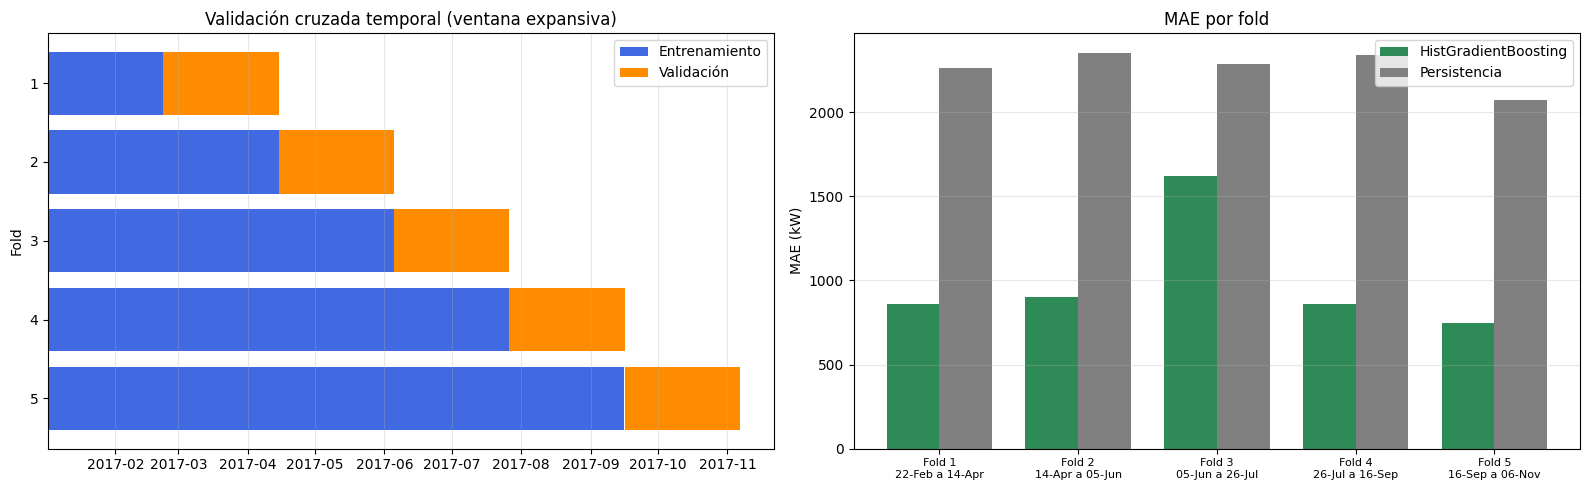

In [41]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
import time

# Desarrollo = entrenamiento + validación (85%). La prueba no se toca.
X_dev, y_dev = X.iloc[:val_end], y.iloc[:val_end]
fechas_dev = df_model["DateTime"].iloc[:val_end].reset_index(drop=True)

N_FOLDS = 5
tscv = TimeSeriesSplit(n_splits=N_FOLDS, gap=HORIZONTE)


def modelo_base():
    return HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, early_stopping=False, random_state=42
    )


inicio = time.time()
resultados_cv = []
for k, (idx_tr, idx_va) in enumerate(tscv.split(X_dev), start=1):
    X_tr, y_tr = X_dev.iloc[idx_tr], y_dev.iloc[idx_tr]
    X_va, y_va = X_dev.iloc[idx_va], y_dev.iloc[idx_va]

    modelo = modelo_base().fit(X_tr, y_tr)
    mae_m, rmse_m, mape_m = metricas(y_va.values, modelo.predict(X_va))
    mae_p, rmse_p, mape_p = metricas(y_va.values, X_va["Zone1_t"].values)

    resultados_cv.append({
        "Fold": k,
        "Entrenamiento": f"{fechas_dev[idx_tr[0]]:%d-%b} a {fechas_dev[idx_tr[-1]]:%d-%b}",
        "Validación": f"{fechas_dev[idx_va[0]]:%d-%b} a {fechas_dev[idx_va[-1]]:%d-%b}",
        "Registros train": len(idx_tr),
        "MAE modelo": mae_m, "MAE persistencia": mae_p,
        "RMSE modelo": rmse_m, "RMSE persistencia": rmse_p,
        "MAPE modelo (%)": mape_m, "MAPE persistencia (%)": mape_p,
    })

cv_df = pd.DataFrame(resultados_cv).set_index("Fold")
cv_df["Mejora MAE vs persistencia (%)"] = (1 - cv_df["MAE modelo"] / cv_df["MAE persistencia"]) * 100

print(f"Tiempo: {time.time() - inicio:.1f} s\n")
display(cv_df.round(2))

print("\n--- Resumen (media ± desviación estándar entre folds) ---")
for met in ["MAE", "RMSE", "MAPE"]:
    sufijo = " (%)" if met == "MAPE" else ""
    m, p = cv_df[f"{met} modelo{sufijo}"], cv_df[f"{met} persistencia{sufijo}"]
    print(f"{met:5s} modelo: {m.mean():,.2f} ± {m.std():,.2f} | persistencia: {p.mean():,.2f} ± {p.std():,.2f}")
print(f"Folds en que el modelo supera a la persistencia (MAE): "
      f"{(cv_df['MAE modelo'] < cv_df['MAE persistencia']).sum()} de {N_FOLDS}")

# Gráficos: esquema de folds y error por fold
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for k, (idx_tr, idx_va) in enumerate(tscv.split(X_dev), start=1):
    axes[0].barh(k, fechas_dev[idx_tr[-1]] - fechas_dev[idx_tr[0]], left=fechas_dev[idx_tr[0]],
                 color="royalblue", label="Entrenamiento" if k == 1 else None)
    axes[0].barh(k, fechas_dev[idx_va[-1]] - fechas_dev[idx_va[0]], left=fechas_dev[idx_va[0]],
                 color="darkorange", label="Validación" if k == 1 else None)
axes[0].set_yticks(range(1, N_FOLDS + 1))
axes[0].set_ylabel("Fold")
axes[0].invert_yaxis()
axes[0].set_title("Validación cruzada temporal (ventana expansiva)")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.3)

ancho = 0.38
pos = np.arange(1, N_FOLDS + 1)
axes[1].bar(pos - ancho / 2, cv_df["MAE modelo"], ancho, label="HistGradientBoosting", color="seagreen")
axes[1].bar(pos + ancho / 2, cv_df["MAE persistencia"], ancho, label="Persistencia", color="gray")
axes[1].set_xticks(pos)
axes[1].set_xticklabels([f"Fold {k}\n{v}" for k, v in cv_df["Validación"].items()], fontsize=8)
axes[1].set_ylabel("MAE (kW)")
axes[1].set_title("MAE por fold")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación de la validación cruzada temporal:**
- El modelo supera a la persistencia en los **5 de 5 folds**: MAE medio de **997 ± 353 kW** frente a **2,261 ± 114 kW** (≈56% menos error; MAPE 3.05% frente a 6.88%). El criterio de éxito se cumple de forma consistente a lo largo del año, no solo en el periodo de validación.
- El error del modelo **no es estable en el tiempo**: el fold 3 (5 de junio a 26 de julio, inicio del verano) casi duplica el MAE de los demás (1,621 kW frente a 750–900 kW). En ese fold el modelo solo se entrenó con enero–junio y debe predecir los meses de mayor consumo, con niveles que no vio antes; los modelos basados en árboles no extrapolan fuera del rango de entrenamiento. Cuando el verano ya forma parte del entrenamiento (fold 4), el error vuelve a bajar.
- La persistencia tiene un error casi constante (≈2,070–2,350 kW), porque solo depende de cuánto cambia el consumo en una hora.
- **Implicancia:** evaluar solo con la partición fija (septiembre–noviembre) da una visión optimista. El mayor riesgo está en los cambios de estación no vistos, y con un solo año de datos no es posible entrenar con un verano anterior.

## Correlaciones no lineales

Es posible que las variables no se correlacionen linealmente con la variable objetivo y aun así aporten información. Por ello, es conveniente realizar un análisis de **información mutua**, que detecta dependencias no lineales e incluso no monótonas (por ejemplo, la hora del día: el consumo sube y baja dentro del mismo ciclo).

- Se calcula **solo con el conjunto de entrenamiento**, para no usar información de validación ni de prueba al analizar las variables.
- Se usa `mutual_info_regression` (estimador por k vecinos más cercanos), indicando cuáles variables son discretas (hora, día, mes, día de la semana, etc.).
- La información mutua vale 0 si la variable y el objetivo son independientes; cuanto mayor, más información comparten (se mide en *nats*, no tiene un máximo fijo).

**Limitación:** es un análisis marginal (evalúa cada variable por separado, sin considerar redundancia entre ellas) y su estimación depende de la muestra y del estimador. Por eso se complementa con la ablación de variables.

Tiempo: 10.0 s



,Información mutua,|Pearson|,Ranking IM,Ranking Pearson,Sube en ranking (IM vs Pearson)
Zone1_lag_24h,1.405,0.957,1,1,0
Zone1_t,1.079,0.910,2,2,0
Zone1_t_minus_1,0.965,0.884,3,3,0
MinuteOfDay,0.886,0.697,4,14,10
Zone1_t_minus_2,0.867,0.855,5,4,-1
Zone1_Rolling_Mean_1h,0.839,0.846,6,6,0
Hour,0.834,0.697,7,13,6
Zone2_t,0.751,0.851,8,5,-3
Zone2_t_minus_1,0.690,0.830,9,7,-2
Zone2_t_minus_2,0.640,0.807,10,8,-2



--- Variables con dependencia principalmente no lineal ---
(suben 5 o más puestos en el ranking al pasar de Pearson a información mutua)
             Información mutua  |Pearson|  Ranking IM  Ranking Pearson
MinuteOfDay              0.886      0.697           4               14
Hour                     0.834      0.697           7               13
Time_Cos                 0.498      0.123          16               28

--- Variables con información mutua cercana a 0 (< 0.05) ---
IsWeekend    0.017
Week_Cos     0.018
Week_Sin     0.033
DayOfWeek    0.033
dtype: float64


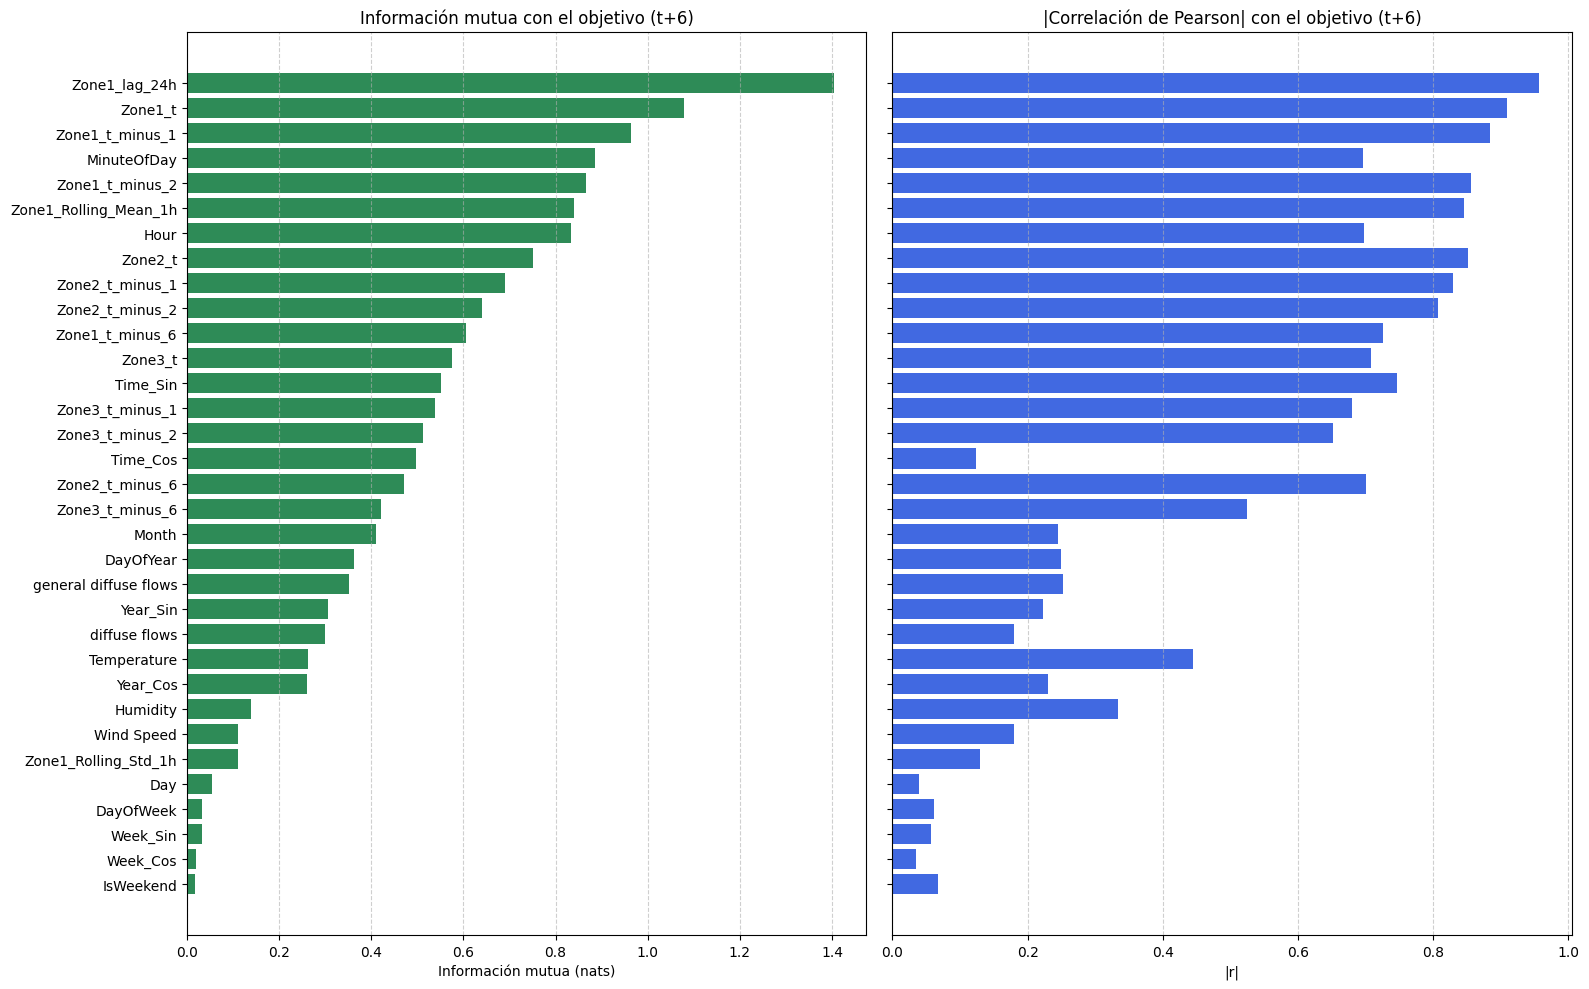

In [42]:
from sklearn.feature_selection import mutual_info_regression

discretas = ["Hour", "MinuteOfDay", "Day", "Month", "DayOfWeek", "DayOfYear", "IsWeekend"]
mascara_discretas = X_train.columns.isin(discretas)

inicio = time.time()
mi = pd.Series(
    mutual_info_regression(X_train, y_train, discrete_features=mascara_discretas,
                           n_neighbors=3, random_state=42),
    index=X_train.columns,
)
print(f"Tiempo: {time.time() - inicio:.1f} s\n")

# Comparación con la correlación de Pearson (también solo en entrenamiento)
pearson_abs = X_train.corrwith(y_train).abs()
comparacion = pd.DataFrame({
    "Información mutua": mi,
    "|Pearson|": pearson_abs,
    "Ranking IM": mi.rank(ascending=False).astype(int),
    "Ranking Pearson": pearson_abs.rank(ascending=False).astype(int),
}).sort_values("Información mutua", ascending=False)
comparacion["Sube en ranking (IM vs Pearson)"] = comparacion["Ranking Pearson"] - comparacion["Ranking IM"]

display(comparacion.round(3))

print("\n--- Variables con dependencia principalmente no lineal ---")
print("(suben 5 o más puestos en el ranking al pasar de Pearson a información mutua)")
no_lineales = comparacion[comparacion["Sube en ranking (IM vs Pearson)"] >= 5]
print(no_lineales[["Información mutua", "|Pearson|", "Ranking IM", "Ranking Pearson"]].round(3))

print("\n--- Variables con información mutua cercana a 0 (< 0.05) ---")
print(mi[mi < 0.05].sort_values().round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharey=True)
orden = comparacion.index
axes[0].barh(orden, comparacion["Información mutua"], color="seagreen")
axes[0].set_title("Información mutua con el objetivo (t+6)")
axes[0].set_xlabel("Información mutua (nats)")
axes[1].barh(orden, comparacion["|Pearson|"], color="royalblue")
axes[1].set_title("|Correlación de Pearson| con el objetivo (t+6)")
axes[1].set_xlabel("|r|")
for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.6)
axes[0].invert_yaxis()  # el eje Y es compartido: se invierte una sola vez
plt.tight_layout()
plt.show()

**Interpretación de la información mutua:**
- Los rezagos de la Zona 1 (rezago diario t−138, t y t−1) concentran la mayor información sobre el objetivo, igual que con Pearson.
- Las variables de **hora del día** son las que más suben en el ranking frente a Pearson: `Time_Cos` pasa del puesto 28 al 16 (|r| = 0.12, pero IM = 0.50), `MinuteOfDay` del 14 al 4 y `Hour` del 13 al 7. Su relación con el consumo es cíclica (mínimo en la madrugada y máximo en la noche) y la correlación lineal no la capta. Esto respalda conservar el calendario diario aunque su correlación lineal sea baja.
- `Temperature` y `Humidity` bajan en el ranking (del puesto 18 al 24 y del 19 al 26): tienen relación lineal con el consumo, pero comparten menos información con el objetivo que los rezagos y la hora del día.
- Las variables **semanales** (`IsWeekend`, `DayOfWeek`, `Week_Sin`, `Week_Cos`) tienen información mutua cercana a 0: por sí solas casi no dicen nada del consumo en t+6. Como el análisis es marginal, esto no significa que no aporten dentro del modelo; eso se evalúa con la ablación.

## Ablación de variables

La información mutua mide cada variable por separado. La **ablación** mide cuánto aporta cada **grupo de variables dentro del modelo**, considerando que muchas son redundantes entre sí (por ejemplo, `Hour`, `MinuteOfDay`, `Time_Sin` y `Time_Cos` describen el mismo ciclo diario).

Procedimiento (*leave-one-group-out*):
1. Se entrena el modelo con todas las variables y se mide el MAE en cada fold de la validación cruzada temporal.
2. Se repite quitando un grupo a la vez, con los mismos folds.
3. **ΔMAE = MAE sin el grupo − MAE con todas las variables.** Si es positivo, quitar el grupo empeora el modelo (el grupo aporta). Si es cercano a 0 o negativo, el grupo es redundante o introduce ruido.

Los grupos de calendario se separan por ciclo (diario, semanal, anual) para verificar la limitación señalada antes: con un solo año de datos, el patrón anual no se puede aprender completamente.

Clima                                         ΔMAE =    +12.2 kW
Calendario diario                             ΔMAE =    +42.7 kW
Calendario semanal                            ΔMAE =    +86.0 kW
Calendario anual (día, mes, día del año)      ΔMAE =    -76.3 kW
Zona 1 reciente (t, t−1, t−2, t−6)            ΔMAE =    +92.6 kW
Zona 1 rezago diario (t−138)                  ΔMAE =   +188.2 kW
Zona 1 estadísticas móviles (1 h)             ΔMAE =    +17.5 kW
Zonas 2 y 3 (rezagos)                         ΔMAE =    +35.4 kW

Tiempo: 149.1 s
MAE con todas las variables: 997 ± 353 kW



,N° variables,ΔMAE medio (kW),ΔMAE desv. est. (kW),ΔMAE (%),Folds en que empeora
Grupo,,,,,
Zona 1 rezago diario (t−138),1,188.15,179.60,18.87,4 de 5
"Zona 1 reciente (t, t−1, t−2, t−6)",4,92.64,35.08,9.29,5 de 5
Calendario semanal,4,85.97,62.13,8.62,5 de 5
Calendario diario,4,42.73,48.92,4.28,4 de 5
Zonas 2 y 3 (rezagos),8,35.36,56.99,3.55,4 de 5
Zona 1 estadísticas móviles (1 h),2,17.49,43.70,1.75,3 de 5
Clima,5,12.19,28.09,1.22,3 de 5
"Calendario anual (día, mes, día del año)",5,-76.34,95.73,-7.65,1 de 5


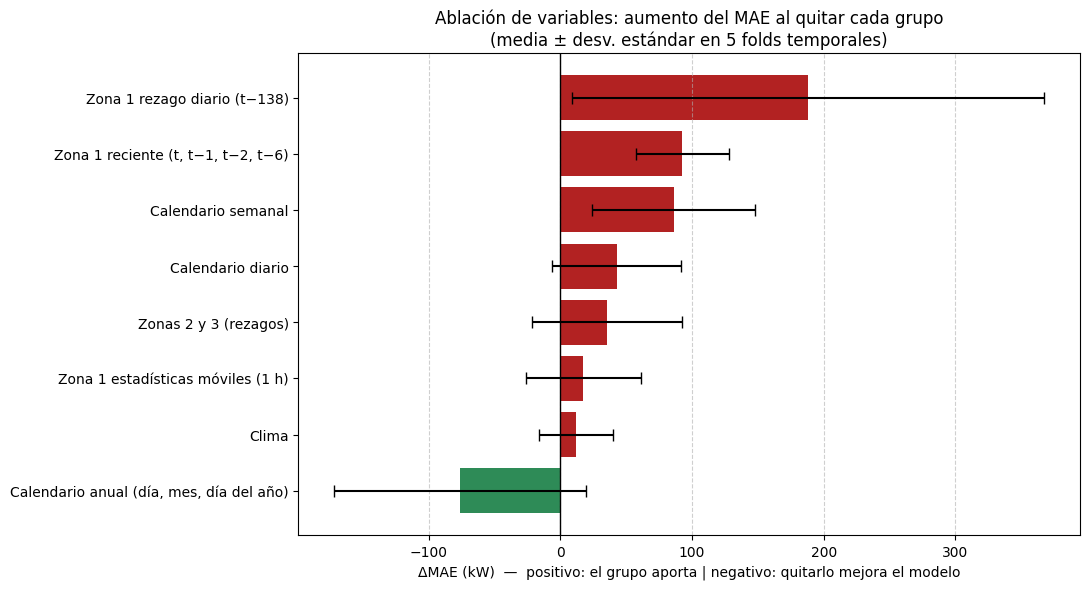

In [43]:
grupos = {
    "Clima": ["Temperature", "Humidity", "Wind Speed", "general diffuse flows", "diffuse flows"],
    "Calendario diario": ["Hour", "MinuteOfDay", "Time_Sin", "Time_Cos"],
    "Calendario semanal": ["DayOfWeek", "IsWeekend", "Week_Sin", "Week_Cos"],
    "Calendario anual (día, mes, día del año)": ["Day", "Month", "DayOfYear", "Year_Sin", "Year_Cos"],
    "Zona 1 reciente (t, t−1, t−2, t−6)": ["Zone1_t", "Zone1_t_minus_1", "Zone1_t_minus_2", "Zone1_t_minus_6"],
    "Zona 1 rezago diario (t−138)": ["Zone1_lag_24h"],
    "Zona 1 estadísticas móviles (1 h)": ["Zone1_Rolling_Mean_1h", "Zone1_Rolling_Std_1h"],
    "Zonas 2 y 3 (rezagos)": [c for c in feature_cols if c.startswith(("Zone2", "Zone3"))],
}
# Cada variable predictora pertenece a exactamente un grupo
assert sorted(sum(grupos.values(), [])) == sorted(feature_cols)


def mae_por_fold(columnas):
    maes = []
    for idx_tr, idx_va in tscv.split(X_dev):
        modelo = modelo_base().fit(X_dev.iloc[idx_tr][columnas], y_dev.iloc[idx_tr])
        pred = modelo.predict(X_dev.iloc[idx_va][columnas])
        maes.append(metricas(y_dev.iloc[idx_va].values, pred)[0])
    return np.array(maes)


inicio = time.time()
mae_todas = mae_por_fold(feature_cols)

filas = []
for nombre, cols_grupo in grupos.items():
    restantes = [c for c in feature_cols if c not in cols_grupo]
    delta = mae_por_fold(restantes) - mae_todas
    filas.append({
        "Grupo": nombre,
        "N° variables": len(cols_grupo),
        "ΔMAE medio (kW)": delta.mean(),
        "ΔMAE desv. est. (kW)": delta.std(ddof=1),
        "ΔMAE (%)": delta.mean() / mae_todas.mean() * 100,
        "Folds en que empeora": f"{(delta > 0).sum()} de {N_FOLDS}",
    })
    print(f"{nombre:45s} ΔMAE = {delta.mean():+8.1f} kW")

ablacion = pd.DataFrame(filas).set_index("Grupo").sort_values("ΔMAE medio (kW)", ascending=False)
print(f"\nTiempo: {time.time() - inicio:.1f} s")
print(f"MAE con todas las variables: {mae_todas.mean():,.0f} ± {mae_todas.std(ddof=1):,.0f} kW\n")
display(ablacion.round(2))

colores = ["firebrick" if v > 0 else "seagreen" for v in ablacion["ΔMAE medio (kW)"]]
plt.figure(figsize=(11, 6))
plt.barh(ablacion.index, ablacion["ΔMAE medio (kW)"], xerr=ablacion["ΔMAE desv. est. (kW)"],
         color=colores, capsize=4)
plt.axvline(0, color="black", linewidth=1)
plt.gca().invert_yaxis()
plt.title("Ablación de variables: aumento del MAE al quitar cada grupo\n(media ± desv. estándar en 5 folds temporales)")
plt.xlabel("ΔMAE (kW)  —  positivo: el grupo aporta | negativo: quitarlo mejora el modelo")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**Interpretación de la ablación:**
- **Rezago diario de la Zona 1:** es el grupo más importante (+188 kW, +18.9% de MAE al quitarlo), aunque con mucha variación entre folds (±180 kW).
- **Rezagos recientes de la Zona 1:** +93 kW. Es el aporte más consistente: empeora el modelo en los 5 folds.
- **Calendario semanal:** +86 kW en los 5 folds, a pesar de que su información mutua era casi 0. Es el caso que justifica combinar ambos análisis: por sí solo no informa sobre el consumo, pero sí junto con los rezagos. Una explicación posible es que el rezago de 24 h de un lunes corresponde a un domingo, y el modelo necesita el día de la semana para corregir esa diferencia.
- **Calendario diario:** +43 kW. Aporta, aunque es en parte redundante con los rezagos, que ya contienen el ciclo diario.
- **Zonas 2 y 3, estadísticas móviles y clima:** aportes pequeños (+12 a +35 kW), no consistentes entre folds y con una desviación mayor que la media, por lo que su efecto no se distingue de 0.
- **Calendario anual:** quitarlo **mejora** el MAE en 76 kW (−7.7%) y solo ayuda en 1 de 5 folds. Esto confirma la limitación señalada antes: con un solo año de datos, `Month`, `DayOfYear`, `Day`, `Year_Sin` y `Year_Cos` funcionan como identificadores de cada época; el modelo aprende el nivel de cada periodo y no generaliza a fechas que no vio.

**Conclusión:** la información mutua y la ablación coinciden en que los rezagos de la Zona 1 son las variables clave, y discrepan en el calendario semanal, que solo aporta en combinación con otras variables. Para la fase de modelado se propone evaluar la exclusión del calendario anual y validar con la validación cruzada temporal, no solo con la partición fija.

## Revisión de data leakage

- **Variables disponibles en t:** el clima observado, el calendario, los rezagos (t, t−1, t−2, t−6, t−138) y las estadísticas móviles (t−5 a t) se conocen al momento de predecir. Ninguna usa información de t+1 en adelante.
- **El objetivo no se filtra como predictora:** se eliminaron Zone 1/2/3 Power Consumption porque duplican Zone1_t, Zone2_t y Zone3_t, y Target_Zone1_t_plus_6 se separa como y.
- **Partición cronológica:** entrenamiento, validación y prueba no se mezclan ni se barajan, así el modelo nunca ve datos del futuro al entrenar.
- **Filas eliminadas:** solo las que no tienen historial suficiente o no tienen objetivo; no se imputa nada que pueda traer información futura.

## Verificación final de la estructura y calidad del dataset

In [44]:
print("--- Estructura del dataset final ---")
df_model.info()

print(f"\nDimensiones finales: {df_model.shape}")
print(f"Valores nulos: {df_model.isnull().sum().sum()}")
print(f"Filas duplicadas: {df_model.duplicated().sum()}")
print(f"Fechas duplicadas: {df_model['DateTime'].duplicated().sum()}")
print(f"Orden cronológico correcto: {df_model['DateTime'].is_monotonic_increasing}")

display(df_model.head())

--- Estructura del dataset final ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52272 entries, 0 to 52271
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DateTime                  52272 non-null  datetime64[ns]
 1   Temperature               52272 non-null  float64       
 2   Humidity                  52272 non-null  float64       
 3   Wind Speed                52272 non-null  float64       
 4   general diffuse flows     52272 non-null  float64       
 5   diffuse flows             52272 non-null  float64       
 6   Zone 1 Power Consumption  52272 non-null  float64       
 7   Zone 2 Power Consumption  52272 non-null  float64       
 8   Zone 3 Power Consumption  52272 non-null  float64       
 9   Hour                      52272 non-null  int32         
 10  MinuteOfDay               52272 non-null  int32         
 11  Day                       52272 non-null  i

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Hour,...,Zone3_t_minus_1,Zone1_t_minus_2,Zone2_t_minus_2,Zone3_t_minus_2,Zone1_t_minus_6,Zone2_t_minus_6,Zone3_t_minus_6,Zone1_lag_24h,Zone1_Rolling_Mean_1h,Zone1_Rolling_Std_1h
0,2017-01-01 23:00:00,12.11,69.94,0.074,0.088,0.082,32117.46835,21253.49544,20686.26506,23,...,21264.57831,33678.98734,22489.96960,21813.97590,36953.92405,24000.00000,23976.86747,34055.69620,34166.075947,1544.173177
1,2017-01-01 23:10:00,12.07,70.70,0.076,0.033,0.078,31357.97468,20768.38906,20397.10843,23,...,20686.26506,33077.46835,21760.48632,21264.57831,36394.93671,23872.34043,23415.90361,29814.68354,33326.582275,1456.809437
2,2017-01-01 23:20:00,11.99,70.80,0.075,0.055,0.134,30701.77215,20337.99392,19905.54217,23,...,20397.10843,32117.46835,21253.49544,20686.26506,35289.11392,23306.99088,22698.79518,29128.10127,32562.025313,1424.238907
3,2017-01-01 23:30:00,11.32,74.70,0.075,0.070,0.100,29681.01266,19823.70821,19252.04819,23,...,19905.54217,31357.97468,20768.38906,20397.10843,34438.48101,22975.07599,22322.89157,28228.86076,31769.113922,1493.263500
4,2017-01-01 23:40:00,11.37,74.80,0.074,0.084,0.082,28830.37975,19488.14590,18847.22892,23,...,19252.04819,30701.77215,20337.99392,19905.54217,33678.98734,22489.96960,21813.97590,27335.69620,30961.012657,1563.301349


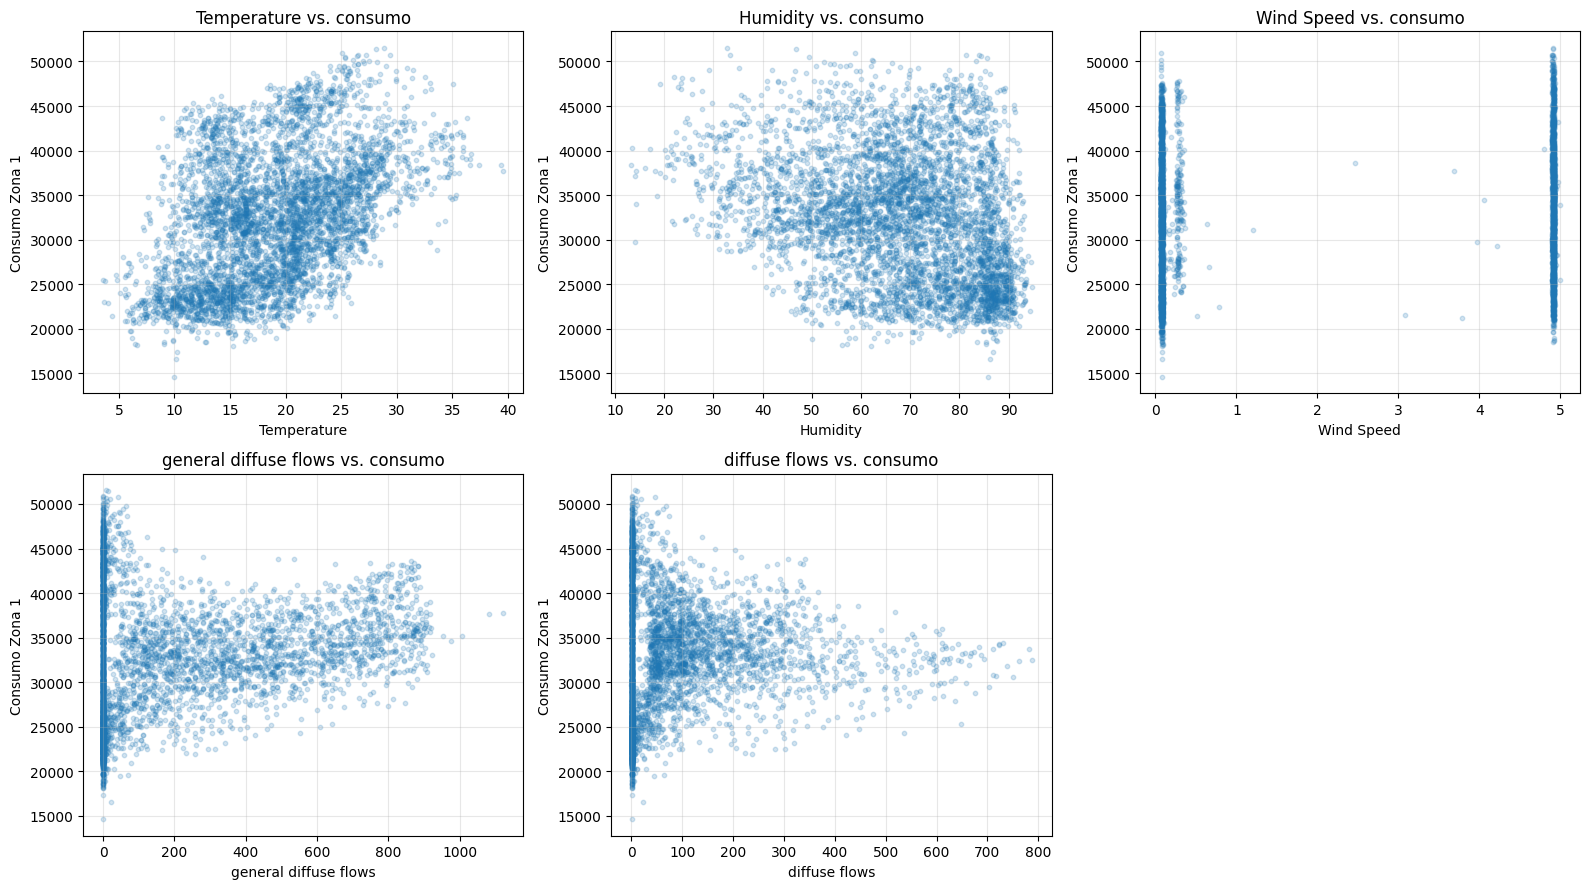

Correlación de cada variable climática con el consumo de Zone 1:
Temperature              0.440
Humidity                -0.287
Wind Speed               0.167
general diffuse flows    0.188
diffuse flows            0.080
dtype: float64


In [45]:
clima_cols = ["Temperature", "Humidity", "Wind Speed", "general diffuse flows", "diffuse flows"]
muestra = df.sample(n=5000, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, clima_cols):
    ax.scatter(muestra[col], muestra["Zone 1 Power Consumption"], alpha=0.2, s=10)
    ax.set_title(f"{col} vs. consumo")
    ax.set_xlabel(col)
    ax.set_ylabel("Consumo Zona 1")
    ax.grid(alpha=0.3)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

print("Correlación de cada variable climática con el consumo de Zone 1:")
print(df[clima_cols].corrwith(df["Zone 1 Power Consumption"]).round(3))